# 07 — Deep Learning for Phone IMU with PyTorch: From Neurons to a 1D CNN

This notebook follows the **PyTorch edition** of Géron's *Hands-On Machine Learning*.

It connects most directly to:

- Chapter 9: **Introduction to Artificial Neural Networks**
- Chapter 10: **Building Neural Networks with PyTorch**
- Chapter 11: **Training Deep Neural Networks**
- Chapter 12: **Deep Computer Vision with CNNs**
- Chapter 13: **Processing Sequences Using RNNs and CNNs**, especially the section on **one-dimensional convolutional layers**

In Notebooks 05–06 we told the computer which features to calculate:

```text
raw 100 × 6 IMU window
        ↓
RMS, SD, range, IQR, FFT power, ...
        ↓
Logistic Regression / Random Forest
```

Now we try:

> **Give the network the raw waveform and let it learn useful features.**

We will spend unusual amounts of time looking inside the CNN rather than treating it as a black box.

Our input is one 2-second window:

```text
100 time samples × 6 channels
ax ay az gx gy gz
```

We will:

1. load the same blinded multi-subject data,
2. convert NumPy arrays to PyTorch tensors,
3. manually slide a tiny convolution kernel across real IMU data,
4. understand PyTorch's `[batch, channels, time]` convention,
5. build an `nn.Module` 1D CNN,
6. calculate parameter counts and receptive field,
7. inspect gradients after `loss.backward()`,
8. train using an explicit PyTorch training loop,
9. plot learning curves,
10. visualize learned convolution kernels and feature maps,
11. explore time-shift / gait-phase tolerance,
12. evaluate with leave-one-subject-out validation,
13. compare raw-waveform CNNs with our hand-feature models.

The hidden competition subjects stay in the vault. 🔐


## 0. PyTorch setup and device

Géron's current PyTorch notebooks use the same basic device pattern:

```text
CUDA GPU if available
    ↓
Apple MPS if available
    ↓
CPU otherwise
```

For **our tiny phone-IMU model, CPU is absolutely fine**. A GPU or Apple Silicon MPS can make repeated cross-validation faster, but it is not required.

The important PyTorch imports are:

- `torch`
- `torch.nn` for layers and loss functions
- `torch.nn.functional` for functions such as ReLU
- `TensorDataset` and `DataLoader` for minibatches

Unlike Keras, PyTorch makes the training loop very explicit. That is useful here because we want to see the machinery.


In [ ]:
# We probably need to install pytorch: on windows use your conda terminal
#conda activate handson-ml-ai
#python -m pip install "torch>=2.8,<3" "torchvision>=0.23,<1"
#python -c "import torch; print('torch:', torch.__version__); print('CUDA:', torch.cuda.is_available()); print('MPS:', hasattr(torch.backends, 'mps') and torch.backends.mps.is_available())"

In [5]:
%matplotlib inline

from pathlib import Path
from collections import Counter
import copy
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import LeaveOneGroupOut

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

print("PyTorch:", torch.__version__)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Device:", device)


PyTorch: 2.14.1
Device: mps


## 1. Load the blinded development data

This is the same dataset used in Notebook 06.

The anonymous subject IDs are used for **grouped validation only**. They are not predictor variables.

We will also convert the text activity labels into integer class indices because `nn.CrossEntropyLoss()` expects integer target labels:

```text
StairsDown → 0
Standing   → 1
Walking    → 2
```

The exact numbering is arbitrary.


In [6]:
DATA_CANDIDATES = [
    Path("train_blinded_20261015.npz"),
    Path("train_blinded.npz"),
    Path("imu_harmonized_20261015/train_blinded_20261015.npz"),
    Path("STUDENT_SHARE_BUNDLE_20261015/train_blinded_20261015.npz")
]

DATA_PATH = next(
    (p for p in DATA_CANDIDATES if p.exists()),
    None,
)

assert DATA_PATH is not None, (
    "Could not find the blinded training NPZ. "
    "Put train_blinded_20261015.npz beside this notebook."
)

data = np.load(DATA_PATH, allow_pickle=False)

X_windows = data["X_windows"].astype(np.float32)
y_windows = data["y_windows"].astype(str)
subject_ids = data["subject_id"].astype(str)

CHANNELS = data["channel_names"].astype(str).tolist()
FS = float(data["sample_rate_hz"])

class_names = np.unique(y_windows)

class_to_index = {
    name: i
    for i, name in enumerate(class_names)
}

y_int = np.array(
    [class_to_index[name] for name in y_windows],
    dtype=np.int64,
)

print("X_windows:", X_windows.shape)
print("Classes:", class_names)
print("Class mapping:", class_to_index)
print("Subjects:", np.unique(subject_ids))
print("Sampling rate:", FS, "Hz")

display(
    pd.crosstab(
        subject_ids,
        y_windows,
        margins=True,
    )
)


X_windows: (2179, 100, 6)
Classes: ['StairsDown' 'Standing' 'Walking']
Class mapping: {np.str_('StairsDown'): 0, np.str_('Standing'): 1, np.str_('Walking'): 2}
Subjects: ['subject01' 'subject05' 'subject06' 'subject07' 'subject08' 'subject09'
 'subject10']
Sampling rate: 50.0 Hz


col_0,StairsDown,Standing,Walking,All
row_0,,,,
subject01,33,54,144,231
subject05,139,45,115,299
subject06,73,29,177,279
subject07,85,78,84,247
subject08,144,130,125,399
subject09,154,151,154,459
subject10,8,83,174,265
All,636,570,973,2179


### Your turn

1. What does each dimension of `X_windows.shape` mean?
2. How many raw predictor values are in one window?
3. Why do we keep `subject_ids` outside the predictor array?
4. Why is `"Walking" → 2` no more meaningful than `"Walking" → 0`?


## 2. The first PyTorch-specific surprise: tensor order

Our NumPy windows were stored as:

```text
[window, time, channel]

2179 × 100 × 6
```

But `nn.Conv1d` expects:

```text
[batch, channel, time]

2179 × 6 × 100
```

So we transpose dimensions **once** before feeding data to the network.

This is not a mathematical change to the data. We are just telling PyTorch which dimension is the sensor-channel dimension.


In [7]:
X_tensor = torch.from_numpy(
    X_windows
).permute(
    0, 2, 1
).contiguous()

y_tensor = torch.from_numpy(y_int)

print("NumPy shape: ", X_windows.shape)
print("PyTorch shape:", X_tensor.shape)
print("Labels shape: ", y_tensor.shape)
print()
print(
    "PyTorch convention:",
    "[batch, channels, time]",
)


NumPy shape:  (2179, 100, 6)
PyTorch shape: torch.Size([2179, 6, 100])
Labels shape:  torch.Size([2179])

PyTorch convention: [batch, channels, time]


## 3. Dense ANN versus CNN: why bother convolving?

A dense neural network could flatten one raw window:

```text
100 × 6
  ↓
600 numbers
  ↓
Dense / Linear layer
```

If the first hidden layer has 64 neurons:

```text
(600 inputs + 1 bias) × 64
= 38,464 parameters
```

And that is just the first layer.

More importantly, a dense layer treats a useful pattern at sample 20 and the exact same pattern at sample 70 as occurring at completely different input coordinates.

A convolutional layer learns a **small detector** and slides the same detector along time.

That is **weight sharing**.


### Your turn

Suppose one `Conv1d` filter:

- sees all 6 channels,
- is 9 samples wide,
- has one bias.

How many parameters are in **one** filter?

How many are in **32 filters**?


## 4. A convolution is a sliding dot product

Before using `nn.Conv1d`, let's do one by hand.

We'll use acceleration magnitude so we can see a single waveform.

Our toy kernel is:

```text
[-1, -0.5, 0, +0.5, +1]
```

It responds positively to a locally increasing signal.

At one location:

$$
z_t = \sum_i x_{t+i}k_i
$$

Then we slide the **same weights** to the next location and repeat.

Technical note: PyTorch's `Conv1d` actually computes cross-correlation, meaning it does not mathematically reverse the kernel first. Deep-learning people still conventionally call this convolution.


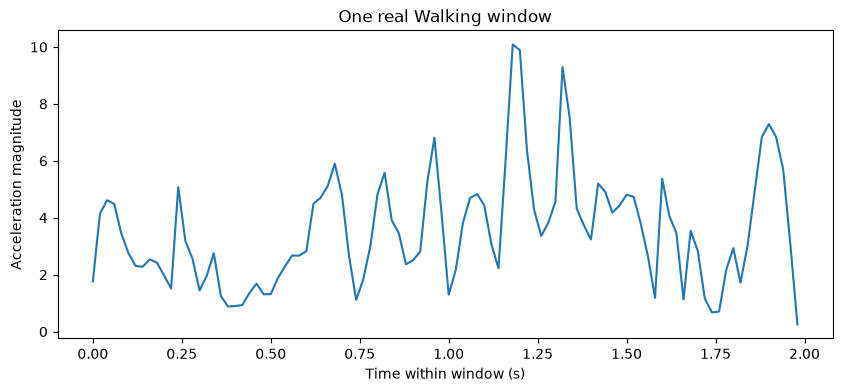

In [31]:
acc_idx = [
    CHANNELS.index(c)
    for c in ["ax", "ay", "az"]
]

gyro_idx = [
    CHANNELS.index(c)
    for c in ["gx", "gy", "gz"]
]

def magnitude(window, indices):
    return np.sqrt(
        np.sum(
            window[:, indices] ** 2,
            axis=1,
        )
    )


walking_idx = np.where(
    y_windows == "Walking"
)[0][20]

walking_window = X_windows[walking_idx]

walking_amagnitude = magnitude(
    walking_window,
    acc_idx,
)

t = (
    np.arange(len(walking_amagnitude))
    / FS
)

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(t, walking_amagnitude)

ax.set_xlabel("Time within window (s)")
ax.set_ylabel("Acceleration magnitude")
ax.set_title("One real Walking window")

plt.show()


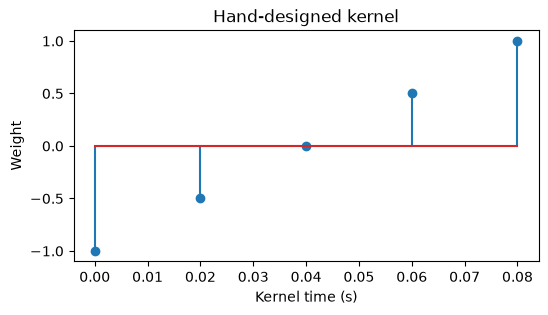

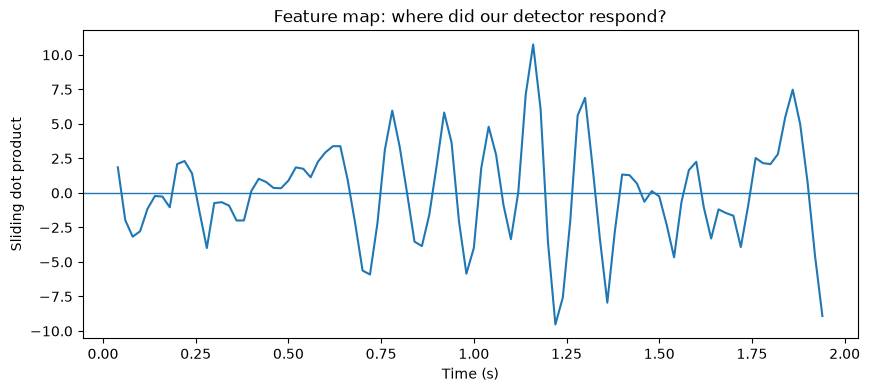

In [32]:
kernel = np.array(
    [-1.0, -0.5, 0.0, 0.5, 1.0],
    dtype=float,
)

def sliding_dot_product(x, kernel):
    output = []

    for start in range(
        len(x) - len(kernel) + 1
    ):
        patch = x[
            start:start + len(kernel)
        ]

        output.append(
            np.sum(patch * kernel)
        )

    return np.asarray(output)


manual_activation = sliding_dot_product(
    walking_amagnitude,
    kernel,
)

t_activation = (
    np.arange(len(manual_activation))
    + (len(kernel) - 1) / 2
) / FS


fig, ax = plt.subplots(figsize=(6, 3))
ax.stem(
    np.arange(len(kernel)) / FS,
    kernel,
)
ax.set_xlabel("Kernel time (s)")
ax.set_ylabel("Weight")
ax.set_title("Hand-designed kernel")
plt.show()


fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    t_activation,
    manual_activation,
)
ax.axhline(0, linewidth=1)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Sliding dot product")
ax.set_title(
    "Feature map: where did our detector respond?"
)
plt.show()


### Your turn

Change the kernel weights.

Can you make a detector that prefers:

- a decreasing edge?
- a sharp central peak?
- an alternating local oscillation?

Our CNN will do something much stranger and more useful:

> **gradient descent will learn these detector weights from the activity labels.**


## 5. A real first-layer kernel is `channels × time`

For our data, one width-9 first-layer filter contains:

```text
6 channels × 9 time offsets = 54 weights
```

plus one bias.

PyTorch stores all first-layer Conv1d weights as:

```text
[out_channels, in_channels, kernel_size]

[32, 6, 9]
```

So each filter can combine accelerometer and gyroscope signals at several neighboring times.


PyTorch kernel shape: (6, 9)


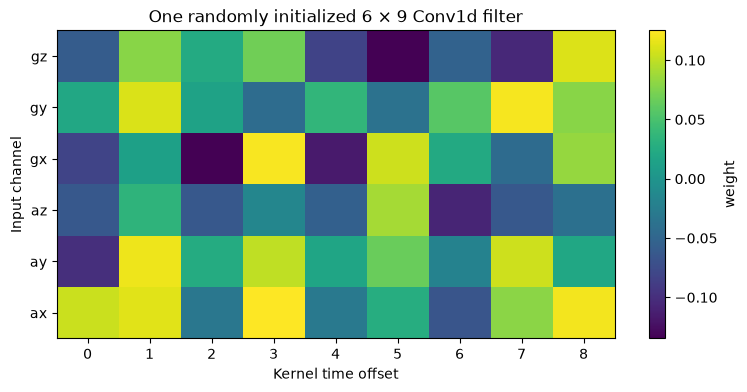

In [10]:
torch.manual_seed(42)

demo_conv = nn.Conv1d(
    in_channels=6,
    out_channels=1,
    kernel_size=9,
    bias=True,
)

demo_weights = (
    demo_conv.weight
    .detach()
    .cpu()
    .numpy()[0]
)

print(
    "PyTorch kernel shape:",
    demo_weights.shape,
)

fig, ax = plt.subplots(figsize=(9, 4))

im = ax.imshow(
    demo_weights,
    aspect="auto",
    origin="lower",
)

ax.set_yticks(
    np.arange(len(CHANNELS)),
    CHANNELS,
)

ax.set_xlabel("Kernel time offset")
ax.set_ylabel("Input channel")
ax.set_title(
    "One randomly initialized 6 × 9 Conv1d filter"
)

plt.colorbar(
    im,
    ax=ax,
    label="weight",
)

plt.show()


## 6. Build the IMU CNN as an `nn.Module`

This is where our little OOP primer comes back.

`nn.Module` defines the interface PyTorch expects. We subclass it and define:

```python
__init__()
forward()
```

PyTorch then knows:

- which objects are trainable parameters,
- how to move them to CPU/GPU/MPS,
- how to collect gradients,
- how an optimizer should update them.

Our network:

```text
Input: [batch, 6, 100]
       ↓
channel standardization
       ↓
Conv1d(6 → 32, kernel 9) + ReLU
       ↓
MaxPool1d(2)
       ↓
Conv1d(32 → 64, kernel 7) + ReLU
       ↓
MaxPool1d(2)
       ↓
Conv1d(64 → 64, kernel 5) + ReLU
       ↓
AdaptiveAvgPool1d(1)
       ↓
Linear(64 → 32) + ReLU
       ↓
Linear(32 → 3)
       ↓
LOGITS
```

Notice: **no softmax inside `forward()`**.

`nn.CrossEntropyLoss()` expects raw logits and internally handles the log-softmax mathematics in a numerically stable way. We only call `softmax()` later when we want probabilities.


In [11]:
class IMUCNN(nn.Module):

    def __init__(
        self,
        channel_mean,
        channel_std,
        n_classes,
    ):
        super().__init__()

        # These are model state, but NOT trainable parameters.
        self.register_buffer(
            "channel_mean",
            channel_mean.clone(),
        )

        self.register_buffer(
            "channel_std",
            channel_std.clone().clamp_min(1e-6),
        )

        self.conv1 = nn.Conv1d(
            in_channels=6,
            out_channels=32,
            kernel_size=9,
            padding=4,
        )

        self.pool1 = nn.MaxPool1d(2)

        self.conv2 = nn.Conv1d(
            in_channels=32,
            out_channels=64,
            kernel_size=7,
            padding=3,
        )

        self.pool2 = nn.MaxPool1d(2)

        self.conv3 = nn.Conv1d(
            in_channels=64,
            out_channels=64,
            kernel_size=5,
            padding=2,
        )

        self.gap = nn.AdaptiveAvgPool1d(1)

        self.fc1 = nn.Linear(
            64,
            32,
        )

        self.fc2 = nn.Linear(
            32,
            n_classes,
        )


    def standardize(self, x):
        return (
            x - self.channel_mean
        ) / self.channel_std


    def forward_features(self, x):
        x = self.standardize(x)

        a1 = F.relu(
            self.conv1(x)
        )

        p1 = self.pool1(a1)

        a2 = F.relu(
            self.conv2(p1)
        )

        p2 = self.pool2(a2)

        a3 = F.relu(
            self.conv3(p2)
        )

        gap = (
            self.gap(a3)
            .squeeze(-1)
        )

        return a1, a2, a3, gap


    def forward(self, x):
        _, _, _, gap = (
            self.forward_features(x)
        )

        x = F.relu(
            self.fc1(gap)
        )

        logits = self.fc2(x)

        return logits


## 7. Train-only normalization

This is the CNN version of our `StandardScaler` lesson.

For each cross-validation fold, channel mean and SD must be calculated from **training subjects only**.

We calculate one mean and SD per sensor channel, across all training windows and time samples:

```text
ax mean, ay mean, az mean, gx mean, gy mean, gz mean
```

These are stored in the model using `register_buffer()`.

A buffer:

- moves with the model to CPU/GPU/MPS,
- is saved with the model,
- but is **not** optimized by gradient descent.


In [12]:
def training_channel_stats(X_train_tensor):
    mean = X_train_tensor.mean(
        dim=(0, 2),
        keepdim=True,
    )

    std = X_train_tensor.std(
        dim=(0, 2),
        keepdim=True,
    )

    return mean, std


def build_model(
    X_train_tensor,
    n_classes,
):
    mean, std = training_channel_stats(
        X_train_tensor
    )

    model = IMUCNN(
        mean,
        std,
        n_classes,
    )

    return model.to(device)


## 8. Parameter counts

Let's compare our hand calculation with PyTorch.

For `Conv1d`:

```text
parameters =
(kernel width × input channels + 1 bias)
× output filters
```

Our network:

```text
Conv1:
(9 × 6 + 1) × 32 = 1,760

Conv2:
(7 × 32 + 1) × 64 = 14,400

Conv3:
(5 × 64 + 1) × 64 = 20,544

Linear 64 → 32:
64 × 32 + 32 = 2,080

Output 32 → 3:
32 × 3 + 3 = 99

TOTAL = 38,883 trainable parameters
```

The input length of 100 does **not** appear in the convolutional parameter formula.

That is weight sharing.


In [13]:
# Temporary model just to inspect its structure.
demo_mean = torch.zeros(1, 6, 1)
demo_std = torch.ones(1, 6, 1)

demo_model = IMUCNN(
    demo_mean,
    demo_std,
    len(class_names),
)

trainable_params = sum(
    p.numel()
    for p in demo_model.parameters()
    if p.requires_grad
)

print(demo_model)
print()
print(
    "Trainable parameters:",
    f"{trainable_params:,}",
)


IMUCNN(
  (conv1): Conv1d(6, 32, kernel_size=(9,), stride=(1,), padding=(4,))
  (pool1): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(32, 64, kernel_size=(7,), stride=(1,), padding=(3,))
  (pool2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv1d(64, 64, kernel_size=(5,), stride=(1,), padding=(2,))
  (gap): AdaptiveAvgPool1d(output_size=1)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=3, bias=True)
)

Trainable parameters: 38,883


## 9. Receptive field: how can small kernels recognize longer patterns?

A deeper convolution does not see only its own kernel width.

It sees the outputs of earlier layers, and those outputs already summarize neighborhoods of the original waveform.

For this architecture:

```text
input                 receptive field ≈  1 sample
Conv9                                    9
Pool2                                   10
Conv7                                   22
Pool2                                   24
Conv5                                   40 samples
```

At 50 Hz:

```text
40 samples / 50 samples/s = 0.8 seconds
```

So one `conv3` activation can depend on roughly 0.8 seconds of the original IMU waveform.

Then Global Average Pooling summarizes those learned features across the entire 2-second window.

This is hierarchical feature learning:

```text
short transients
      ↓
combinations of transients
      ↓
longer movement motifs
      ↓
activity evidence
```


## 10. Hold out one entire subject for the training demo

Before full leave-one-subject-out CV, we train once while holding out a single anonymous person.

That lets us inspect the training process without waiting for seven networks.

The held-out subject must be excluded from:

- normalization statistics,
- minibatch training,
- gradient descent,
- optimizer updates.


In [14]:
DEMO_VAL_SUBJECT = np.unique(
    subject_ids
)[0]

train_mask = (
    subject_ids != DEMO_VAL_SUBJECT
)

val_mask = (
    subject_ids == DEMO_VAL_SUBJECT
)

X_train = X_tensor[train_mask]
y_train = y_tensor[train_mask]

X_val = X_tensor[val_mask]
y_val = y_tensor[val_mask]

print(
    "Validation subject:",
    DEMO_VAL_SUBJECT,
)

print(
    "Training tensor:",
    X_train.shape,
)

print(
    "Validation tensor:",
    X_val.shape,
)

print(
    "Training labels:",
    Counter(y_windows[train_mask]),
)

print(
    "Validation labels:",
    Counter(y_windows[val_mask]),
)


Validation subject: subject01
Training tensor: torch.Size([1948, 6, 100])
Validation tensor: torch.Size([231, 6, 100])
Training labels: Counter({np.str_('Walking'): 829, np.str_('StairsDown'): 603, np.str_('Standing'): 516})
Validation labels: Counter({np.str_('Walking'): 144, np.str_('Standing'): 54, np.str_('StairsDown'): 33})


In [15]:
torch.manual_seed(42)

model = build_model(
    X_train,
    len(class_names),
)

initial_conv1_weights = (
    model.conv1.weight
    .detach()
    .cpu()
    .clone()
)

print(model)


IMUCNN(
  (conv1): Conv1d(6, 32, kernel_size=(9,), stride=(1,), padding=(4,))
  (pool1): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(32, 64, kernel_size=(7,), stride=(1,), padding=(3,))
  (pool2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv1d(64, 64, kernel_size=(5,), stride=(1,), padding=(2,))
  (gap): AdaptiveAvgPool1d(output_size=1)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=3, bias=True)
)


## 11. DataLoader: minibatches for gradient descent

PyTorch's `DataLoader` handles:

- dividing the training set into minibatches,
- shuffling training examples each epoch,
- iterating over batches.

The important conceptual difference is:

```text
dataset = all examples
batch   = one small chunk used for one optimizer update
epoch   = one trip through the whole training dataset
```


In [16]:
def make_loader(
    X,
    y,
    batch_size=128,
    shuffle=False,
):
    dataset = TensorDataset(
        X,
        y,
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
    )


train_loader = make_loader(
    X_train,
    y_train,
    batch_size=128,
    shuffle=True,
)

val_loader = make_loader(
    X_val,
    y_val,
    batch_size=256,
    shuffle=False,
)

X_batch, y_batch = next(
    iter(train_loader)
)

print("One X batch:", X_batch.shape)
print("One y batch:", y_batch.shape)


One X batch: torch.Size([128, 6, 100])
One y batch: torch.Size([128])


## 12. Backpropagation, exposed

This is the core PyTorch training sequence:

```python
optimizer.zero_grad()
logits = model(X_batch)       # forward pass
loss = loss_fn(logits, y)     # how wrong?
loss.backward()               # compute ALL gradients
optimizer.step()              # update ALL parameters
```

Unlike Keras `model.fit()`, PyTorch lets us see each gear turning.

Let's perform a forward/backward pass **without taking the optimizer step yet**, and inspect the gradients.


In [17]:
loss_fn = nn.CrossEntropyLoss()

model.train()
model.zero_grad(set_to_none=True)

X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

logits = model(X_batch)

loss = loss_fn(
    logits,
    y_batch,
)

loss.backward()


gradient_rows = []

for name, parameter in model.named_parameters():

    gradient_rows.append({
        "parameter": name,
        "shape": str(
            tuple(parameter.shape)
        ),
        "gradient_norm": (
            float(
                parameter.grad.norm().item()
            )
            if parameter.grad is not None
            else np.nan
        ),
    })


gradient_table = pd.DataFrame(
    gradient_rows
)

print("Batch loss:", float(loss.item()))

display(gradient_table)


Batch loss: 1.0990705490112305


,parameter,shape,gradient_norm
0,conv1.weight,"(32, 6, 9)",0.010229
1,conv1.bias,"(32,)",0.003411
2,conv2.weight,"(64, 32, 7)",0.060530
3,conv2.bias,"(64,)",0.009419
4,conv3.weight,"(64, 64, 5)",0.099401
5,conv3.bias,"(64,)",0.022523
6,fc1.weight,"(32, 64)",0.055881
7,fc1.bias,"(32,)",0.045133
8,fc2.weight,"(3, 32)",0.040882
9,fc2.bias,"(3,)",0.057992


### Your turn

Why do we clear gradients before each update?

PyTorch **accumulates** gradients by default. If we did not zero them, the new minibatch gradient would be added to the old one.


## 13. Training and evaluation functions

Now we wrap the PyTorch mechanics into reusable functions.

Pay attention to two mode switches:

```python
model.train()
model.eval()
```

Layers such as Dropout and BatchNorm behave differently between training and inference. Our current CNN does not use them, but getting the habit right matters.

During evaluation we also use:

```python
with torch.no_grad():
```

because we do not need a computation graph or gradients.


In [18]:
def class_weights_from_labels(
    y_train,
    n_classes,
):
    counts = torch.bincount(
        y_train,
        minlength=n_classes,
    ).float()

    weights = (
        len(y_train)
        / (n_classes * counts)
    )

    return weights


def evaluate_model(
    model,
    loader,
    loss_fn,
):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    all_true = []
    all_pred = []

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)

            loss = loss_fn(
                logits,
                y_batch,
            )

            predictions = logits.argmax(
                dim=1
            )

            total_loss += (
                loss.item()
                * len(y_batch)
            )

            total_correct += (
                predictions == y_batch
            ).sum().item()

            total_examples += len(y_batch)

            all_true.append(
                y_batch.cpu().numpy()
            )

            all_pred.append(
                predictions.cpu().numpy()
            )

    return {
        "loss": total_loss / total_examples,
        "accuracy": total_correct / total_examples,
        "y_true": np.concatenate(all_true),
        "y_pred": np.concatenate(all_pred),
    }


def train_model(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    *,
    max_epochs=40,
    patience=5,
    batch_size=128,
    learning_rate=1e-3,
    verbose=True,
):
    train_loader = make_loader(
        X_train,
        y_train,
        batch_size=batch_size,
        shuffle=True,
    )

    val_loader = make_loader(
        X_val,
        y_val,
        batch_size=256,
        shuffle=False,
    )

    class_weights = class_weights_from_labels(
        y_train,
        len(class_names),
    ).to(device)

    loss_fn = nn.CrossEntropyLoss(
        weight=class_weights
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
    )

    history = []

    best_val_loss = np.inf
    best_state = None
    epochs_without_improvement = 0

    for epoch in range(1, max_epochs + 1):

        model.train()

        train_loss_sum = 0.0
        train_correct = 0
        train_examples = 0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad(
                set_to_none=True
            )

            logits = model(X_batch)

            loss = loss_fn(
                logits,
                y_batch,
            )

            loss.backward()

            optimizer.step()

            train_loss_sum += (
                loss.item()
                * len(y_batch)
            )

            train_correct += (
                logits.argmax(dim=1)
                == y_batch
            ).sum().item()

            train_examples += len(y_batch)

        val_result = evaluate_model(
            model,
            val_loader,
            loss_fn,
        )

        train_loss = (
            train_loss_sum
            / train_examples
        )

        train_accuracy = (
            train_correct
            / train_examples
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_result["loss"],
            "val_accuracy": val_result["accuracy"],
        })

        if verbose:
            print(
                f"Epoch {epoch:02d} | "
                f"train loss {train_loss:.3f} | "
                f"train acc {train_accuracy:.3f} | "
                f"val loss {val_result['loss']:.3f} | "
                f"val acc {val_result['accuracy']:.3f}"
            )

        if val_result["loss"] < best_val_loss - 1e-4:

            best_val_loss = val_result["loss"]

            best_state = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1

            if epochs_without_improvement >= patience:
                if verbose:
                    print("Early stopping.")
                break

    model.load_state_dict(
        best_state
    )

    return (
        model,
        pd.DataFrame(history),
    )


## 14. Train the demonstration model

We allow up to 40 epochs, but early stopping usually quits sooner.

On this dataset, CPU is enough. Full leave-one-subject-out validation means training seven fresh networks, so that later step takes longer than this single demonstration.


In [34]:
torch.manual_seed(42)

model = build_model(
    X_train,
    len(class_names),
)

initial_conv1_weights = (
    model.conv1.weight
    .detach()
    .cpu()
    .clone()
)

start_time = time.time()

model, history_df = train_model(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    max_epochs=40,
    patience=5,
    batch_size=128,
    learning_rate=1e-3,
    verbose=True,
)

elapsed = time.time() - start_time

print()
print(
    "Epochs trained:",
    len(history_df),
)

print(
    f"Training time: {elapsed:.1f} s"
)


Epoch 01 | train loss 1.045 | train acc 0.415 | val loss 1.011 | val acc 0.329
Epoch 02 | train loss 0.931 | train acc 0.582 | val loss 0.931 | val acc 0.784
Epoch 03 | train loss 0.777 | train acc 0.766 | val loss 0.734 | val acc 0.827
Epoch 04 | train loss 0.542 | train acc 0.818 | val loss 0.600 | val acc 0.835
Epoch 05 | train loss 0.442 | train acc 0.837 | val loss 0.412 | val acc 0.900
Epoch 06 | train loss 0.436 | train acc 0.840 | val loss 0.411 | val acc 0.900
Epoch 07 | train loss 0.408 | train acc 0.848 | val loss 0.465 | val acc 0.870
Epoch 08 | train loss 0.395 | train acc 0.845 | val loss 0.375 | val acc 0.900
Epoch 09 | train loss 0.380 | train acc 0.849 | val loss 0.474 | val acc 0.879
Epoch 10 | train loss 0.379 | train acc 0.854 | val loss 0.391 | val acc 0.887
Epoch 11 | train loss 0.354 | train acc 0.864 | val loss 0.355 | val acc 0.900
Epoch 12 | train loss 0.341 | train acc 0.864 | val loss 0.364 | val acc 0.892
Epoch 13 | train loss 0.326 | train acc 0.867 | val 

## 15. Plot the learning curves

If training performance keeps improving while validation performance gets worse, we are beginning to overfit the training people.

The validation subject acts as our canary in the neural-net coal mine.


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
20,21,0.294915,0.877823,0.310801,0.887446
21,22,0.273582,0.890657,0.333891,0.887446
22,23,0.274491,0.887577,0.326167,0.896104
23,24,0.260207,0.895791,0.353313,0.887446
24,25,0.243391,0.906057,0.324736,0.883117


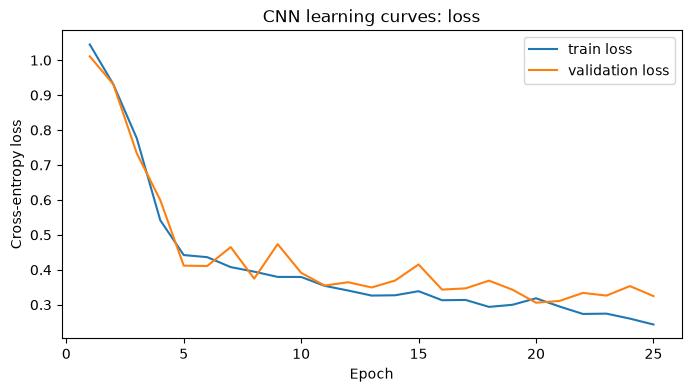

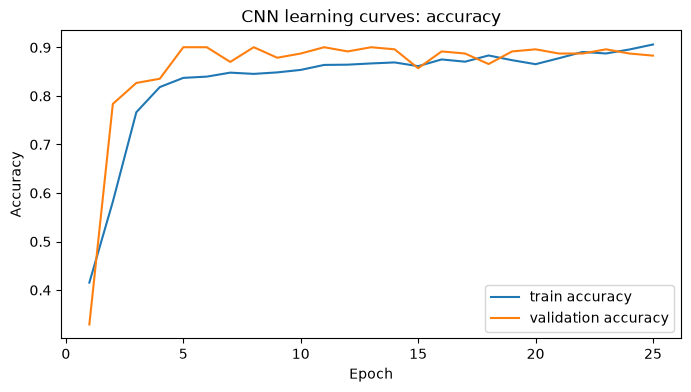

In [35]:
display(
    history_df.tail()
)

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="train loss",
)

ax.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="validation loss",
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss")
ax.set_title("CNN learning curves: loss")
ax.legend()

plt.show()


fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    label="train accuracy",
)

ax.plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    label="validation accuracy",
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.set_title("CNN learning curves: accuracy")
ax.legend()

plt.show()


## 16. Evaluate the unseen demonstration subject

The network returns logits.

For the predicted class:

```python
logits.argmax(dim=1)
```

For interpretable class probabilities:

```python
torch.softmax(logits, dim=1)
```


Accuracy: 0.8961038961038961
Macro F1: 0.8565154673317593

              precision    recall  f1-score   support

  StairsDown       0.79      0.67      0.72        33
    Standing       0.91      0.94      0.93        54
     Walking       0.91      0.93      0.92       144

    accuracy                           0.90       231
   macro avg       0.87      0.85      0.86       231
weighted avg       0.89      0.90      0.89       231



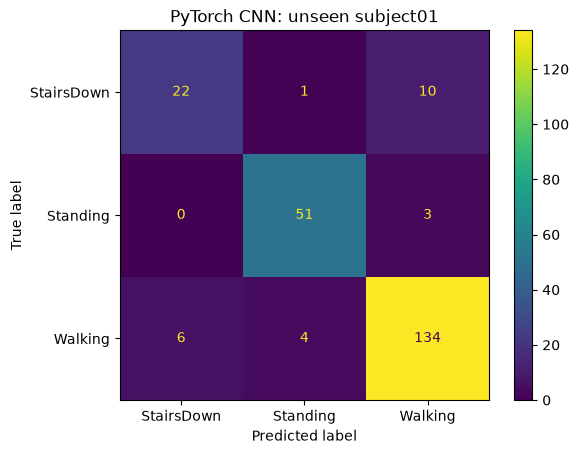

In [36]:
val_loader = make_loader(
    X_val,
    y_val,
    batch_size=256,
    shuffle=False,
)

class_weights = class_weights_from_labels(
    y_train,
    len(class_names),
).to(device)

loss_fn = nn.CrossEntropyLoss(
    weight=class_weights
)

val_result = evaluate_model(
    model,
    val_loader,
    loss_fn,
)

val_pred = val_result["y_pred"]
val_true = val_result["y_true"]

print(
    "Accuracy:",
    accuracy_score(
        val_true,
        val_pred,
    ),
)

print(
    "Macro F1:",
    f1_score(
        val_true,
        val_pred,
        average="macro",
    ),
)

print()

print(
    classification_report(
        val_true,
        val_pred,
        target_names=class_names,
    )
)

ConfusionMatrixDisplay.from_predictions(
    val_true,
    val_pred,
    display_labels=class_names,
    cmap=None,
)

plt.title(
    f"PyTorch CNN: unseen {DEMO_VAL_SUBJECT}"
)

plt.show()


In [37]:
model.eval()

with torch.no_grad():

    example_logits = model(
        X_val[:8].to(device)
    )

    example_probs = torch.softmax(
        example_logits,
        dim=1,
    ).cpu().numpy()

    example_pred = example_probs.argmax(
        axis=1
    )


rows = []

for i in range(len(example_probs)):

    row = {
        "true": class_names[
            int(y_val[i])
        ],
        "predicted": class_names[
            example_pred[i]
        ],
    }

    for j, name in enumerate(class_names):
        row[f"P({name})"] = (
            example_probs[i, j]
        )

    rows.append(row)


display(
    pd.DataFrame(rows)
)


,true,predicted,P(StairsDown),P(Standing),P(Walking)
0,Walking,Standing,0.025362,0.952312,0.022326
1,Walking,Standing,0.047607,0.826966,0.125426
2,Walking,Walking,0.015932,0.475716,0.508352
3,Walking,Walking,0.069294,0.429476,0.501231
4,Walking,StairsDown,0.794616,0.069744,0.135640
5,Walking,Walking,0.430908,0.049207,0.519885
6,Walking,Walking,0.037884,0.006049,0.956068
7,Walking,Walking,0.056262,0.004838,0.938900


## 17. Did the convolution kernels actually change?

Let's compare a few first-layer filters:

```text
random initialization
        ↓
many gradient updates
        ↓
learned kernel
```

Each filter is a `6 × 9` little sensor-time template.


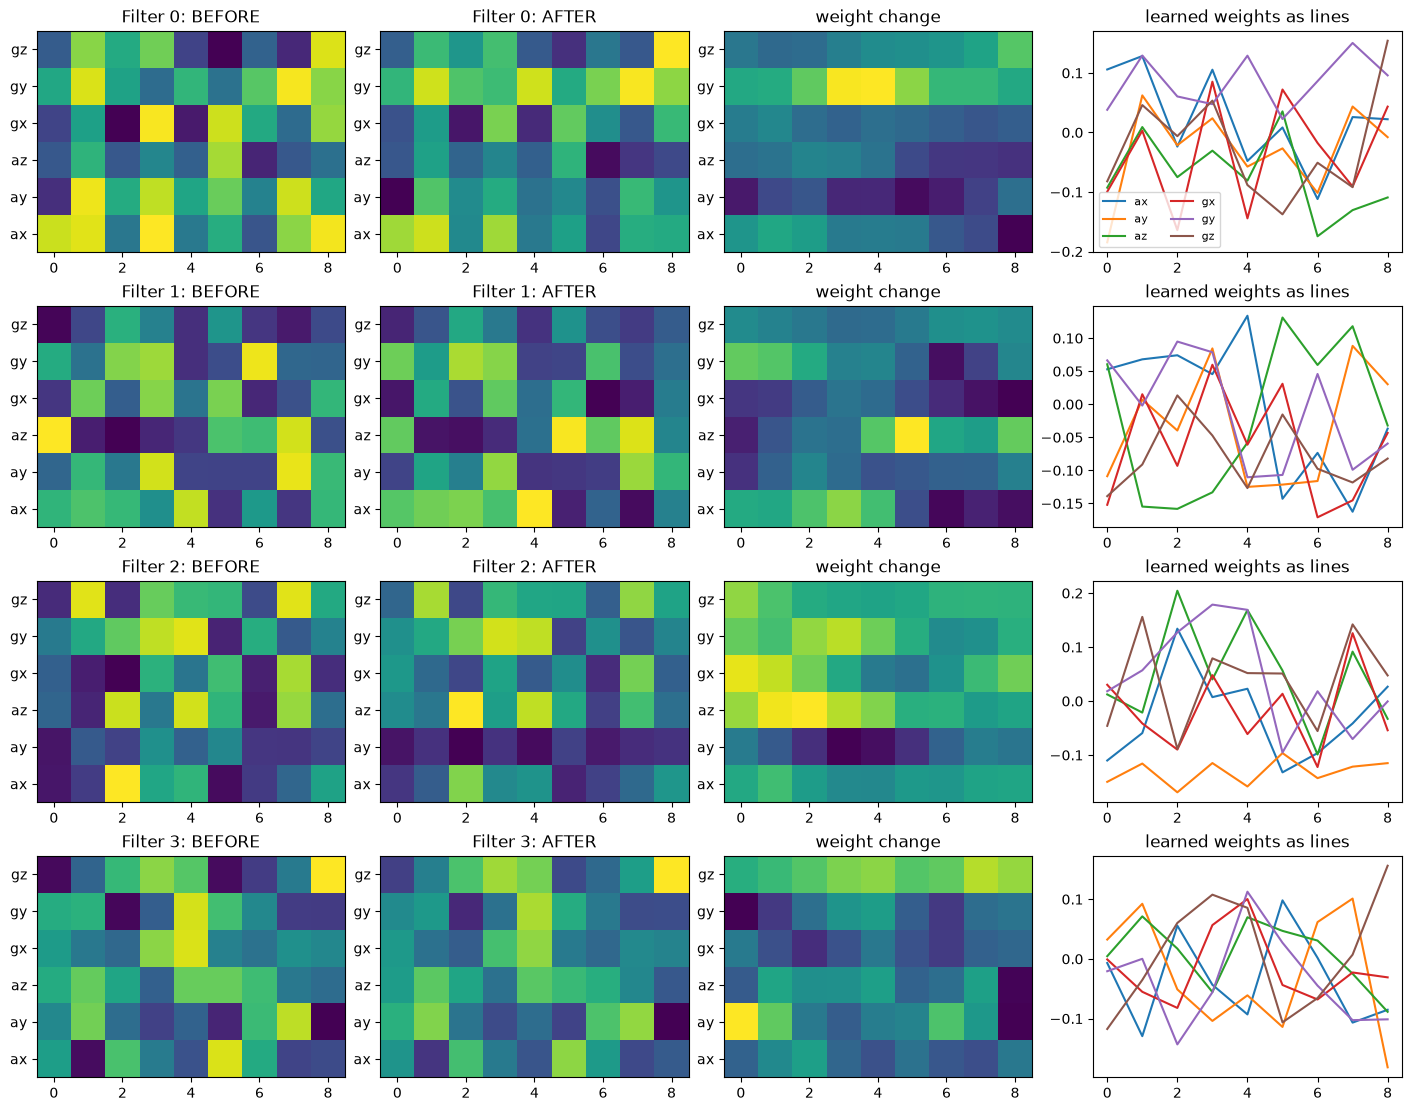

In [38]:
trained_conv1_weights = (
    model.conv1.weight
    .detach()
    .cpu()
)

fig, axes = plt.subplots(
    4,
    4,
    figsize=(14, 11),
    constrained_layout=True,
)

for row, filter_index in enumerate(
    range(4)
):
    before = (
        initial_conv1_weights[
            filter_index
        ].numpy()
    )

    after = (
        trained_conv1_weights[
            filter_index
        ].numpy()
    )

    im1 = axes[row, 0].imshow(
        before,
        aspect="auto",
        origin="lower",
    )

    axes[row, 0].set_title(
        f"Filter {filter_index}: BEFORE"
    )

    axes[row, 1].imshow(
        after,
        aspect="auto",
        origin="lower",
    )

    axes[row, 1].set_title(
        f"Filter {filter_index}: AFTER"
    )

    change = after - before

    axes[row, 2].imshow(
        change,
        aspect="auto",
        origin="lower",
    )

    axes[row, 2].set_title(
        "weight change"
    )

    for channel_i, channel_name in enumerate(CHANNELS):
        axes[row, 3].plot(
            after[channel_i],
            label=channel_name,
        )

    axes[row, 3].set_title(
        "learned weights as lines"
    )

    if row == 0:
        axes[row, 3].legend(
            ncol=2,
            fontsize=8,
        )

    for col in range(3):
        axes[row, col].set_yticks(
            np.arange(len(CHANNELS)),
            CHANNELS,
        )

plt.show()


## 18. Feature maps: what did those kernels detect?

The kernel is the detector.

The **feature map** is the detector's response as it slides through a particular waveform.

Because our `IMUCNN.forward_features()` returns hidden activations, we can inspect them directly.


Input: (1, 6, 100)
Conv1 activation: (32, 100)
Conv2 activation: (64, 50)
Conv3 activation: (64, 25)
Global pooled features: (64,)


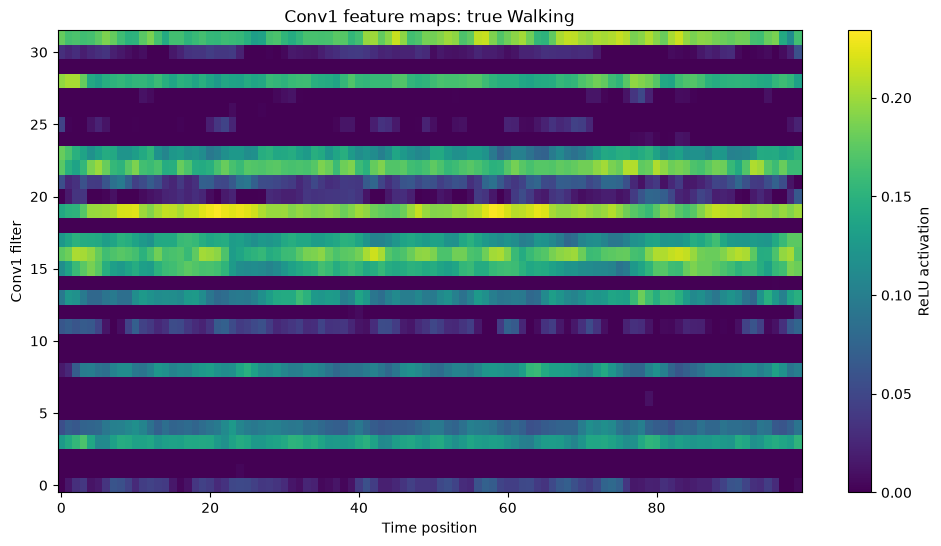

In [39]:
model.eval()

example_index = 0

with torch.no_grad():

    example = (
        X_val[
            example_index:example_index + 1
        ]
        .to(device)
    )

    a1, a2, a3, gap = (
        model.forward_features(example)
    )


a1_np = a1[0].cpu().numpy()
a2_np = a2[0].cpu().numpy()
a3_np = a3[0].cpu().numpy()
gap_np = gap[0].cpu().numpy()

print(
    "Input:",
    tuple(example.shape),
)

print(
    "Conv1 activation:",
    a1_np.shape,
)

print(
    "Conv2 activation:",
    a2_np.shape,
)

print(
    "Conv3 activation:",
    a3_np.shape,
)

print(
    "Global pooled features:",
    gap_np.shape,
)


fig, ax = plt.subplots(figsize=(12, 6))

im = ax.imshow(
    a1_np,
    aspect="auto",
    origin="lower",
)

ax.set_xlabel("Time position")
ax.set_ylabel("Conv1 filter")
ax.set_title(
    f"Conv1 feature maps: true {class_names[int(y_val[example_index])]}"
)

plt.colorbar(
    im,
    ax=ax,
    label="ReLU activation",
)

plt.show()


## 19. Plot the filters that fired most strongly

We can average each Conv1 filter's ReLU activity across time.

The highest averages tell us which learned detectors were most active for this particular window.

This does **not** mean those filters have simple human-readable meanings, but now we can at least inspect what the network constructed.


Most active Conv1 filters: [19 16 31 22]


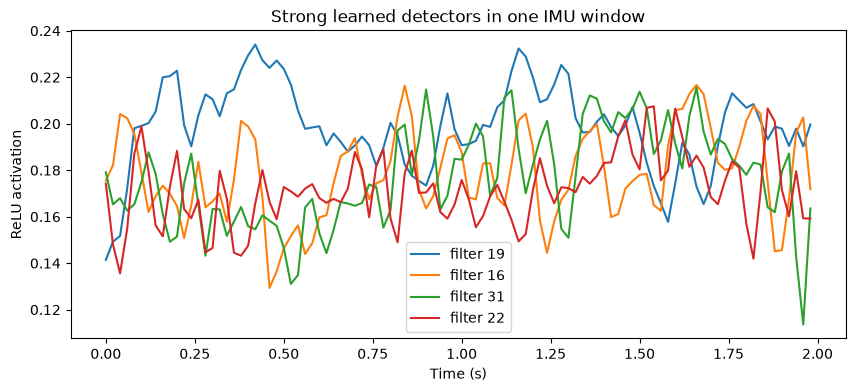

In [40]:
mean_filter_activity = (
    a1_np.mean(axis=1)
)

top_filters = np.argsort(
    mean_filter_activity
)[-4:][::-1]

print(
    "Most active Conv1 filters:",
    top_filters,
)


fig, ax = plt.subplots(figsize=(10, 4))

time_axis = (
    np.arange(a1_np.shape[1])
    / FS
)

for filter_index in top_filters:

    ax.plot(
        time_axis,
        a1_np[filter_index],
        label=f"filter {filter_index}",
    )

ax.set_xlabel("Time (s)")
ax.set_ylabel("ReLU activation")
ax.set_title(
    "Strong learned detectors in one IMU window"
)

ax.legend()

plt.show()


## 20. Global Average Pooling creates learned summary features

Immediately before the dense classifier, our third convolution produces something shaped roughly:

```text
64 filters × 25 time locations
```

Global Average Pooling averages each filter over time:

```text
64 × 25
   ↓
64 numbers
```

Those 64 numbers are a **learned feature vector**.

This is the CNN analogue of our handcrafted RMS/SD/range/FFT feature vector, except the network invented the representation itself.


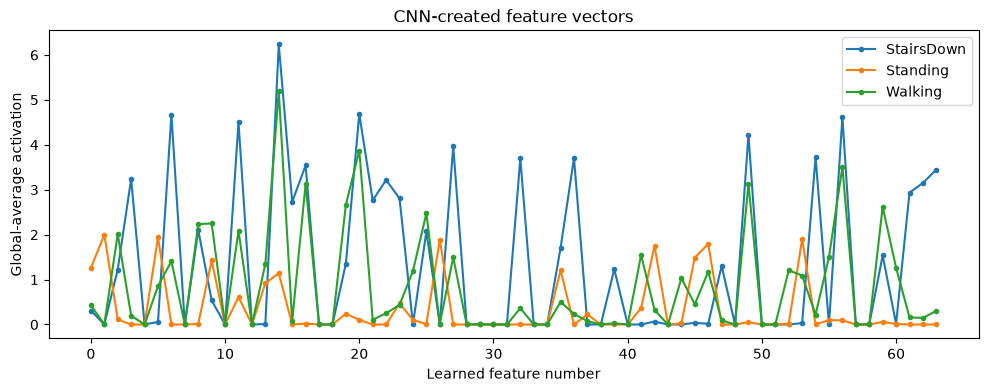

In [41]:
gap_rows = []
gap_labels = []

model.eval()

with torch.no_grad():

    for class_index, class_name in enumerate(
        class_names
    ):

        candidates = np.where(
            y_val.numpy() == class_index
        )[0]

        if len(candidates) == 0:
            continue

        idx = candidates[
            len(candidates) // 2
        ]

        _, _, _, this_gap = (
            model.forward_features(
                X_val[
                    idx:idx + 1
                ].to(device)
            )
        )

        gap_rows.append(
            this_gap[0]
            .cpu()
            .numpy()
        )

        gap_labels.append(
            class_name
        )


gap_rows = np.asarray(
    gap_rows
)

fig, ax = plt.subplots(figsize=(12, 4))

for row, label in zip(
    gap_rows,
    gap_labels,
):

    ax.plot(
        row,
        marker=".",
        label=label,
    )

ax.set_xlabel("Learned feature number")
ax.set_ylabel(
    "Global-average activation"
)

ax.set_title(
    "CNN-created feature vectors"
)

ax.legend()

plt.show()


## 21. Arbitrary gait phase: shift the waveform

A walking window can start at any phase of the gait cycle.

Convolution is **translation equivariant**:

> if a local feature moves in time, the feature-map response tends to move with it.

Pooling makes later representations more tolerant to small shifts.

Global Average Pooling goes further by largely caring about **whether a learned feature occurred**, rather than its exact time coordinate.

It is not perfect invariance, especially at window boundaries.


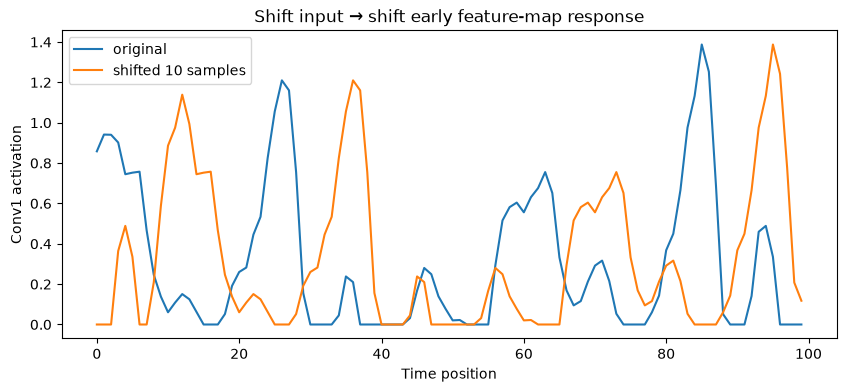

Cosine similarity of final GAP vectors: 0.999453067779541


In [42]:
walking_class = class_to_index[
    "Walking"
]

walking_candidates = np.where(
    y_val.numpy() == walking_class
)[0]

phase_idx = walking_candidates[
    len(walking_candidates) // 2
]

original = X_val[
    phase_idx:phase_idx + 1
]

shift_samples = 10

shifted = torch.roll(
    original,
    shifts=shift_samples,
    dims=2,
)

model.eval()

with torch.no_grad():

    orig_a1, _, _, orig_gap = (
        model.forward_features(
            original.to(device)
        )
    )

    shift_a1, _, _, shift_gap = (
        model.forward_features(
            shifted.to(device)
        )
    )


orig_a1 = (
    orig_a1[0]
    .cpu()
    .numpy()
)

shift_a1 = (
    shift_a1[0]
    .cpu()
    .numpy()
)

orig_gap = (
    orig_gap[0]
    .cpu()
)

shift_gap = (
    shift_gap[0]
    .cpu()
)


best_filter = np.argmax(
    orig_a1.mean(axis=1)
)

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    orig_a1[best_filter],
    label="original",
)

ax.plot(
    shift_a1[best_filter],
    label=f"shifted {shift_samples} samples",
)

ax.set_xlabel("Time position")
ax.set_ylabel("Conv1 activation")
ax.set_title(
    "Shift input → shift early feature-map response"
)

ax.legend()

plt.show()


cosine_similarity = F.cosine_similarity(
    orig_gap.unsqueeze(0),
    shift_gap.unsqueeze(0),
).item()

print(
    "Cosine similarity of final GAP vectors:",
    cosine_similarity,
)


## 22. Honest leave-one-subject-out CNN validation

Now we repeat the same experimental logic as Notebook 06:

```text
train on 6 subjects
test on 1 completely unseen subject
repeat for every development subject
```

For **every fold** we must:

1. create a fresh network,
2. compute normalization statistics from that fold's training subjects only,
3. train only on those subjects,
4. predict the held-out person.

This is the slowest cell. On CPU it is still practical for this small dataset, but expect minutes rather than seconds on some laptops.


In [43]:
logo = LeaveOneGroupOut()

cnn_pred = np.empty_like(
    y_int
)

fold_rows = []

for fold_number, (
    train_idx,
    val_idx,
) in enumerate(
    logo.split(
        X_windows,
        y_int,
        groups=subject_ids,
    ),
    start=1,
):

    held_subject = np.unique(
        subject_ids[val_idx]
    )[0]

    print(
        f"Fold {fold_number}: "
        f"holding out {held_subject}"
    )

    X_train_fold = X_tensor[
        train_idx
    ]

    y_train_fold = y_tensor[
        train_idx
    ]

    X_val_fold = X_tensor[
        val_idx
    ]

    y_val_fold = y_tensor[
        val_idx
    ]

    torch.manual_seed(
        100 + fold_number
    )

    fold_model = build_model(
        X_train_fold,
        len(class_names),
    )

    fold_model, fold_history = train_model(
        fold_model,
        X_train_fold,
        y_train_fold,
        X_val_fold,
        y_val_fold,
        max_epochs=30,
        patience=4,
        batch_size=128,
        learning_rate=1e-3,
        verbose=False,
    )

    fold_model.eval()

    with torch.no_grad():

        logits = fold_model(
            X_val_fold.to(device)
        )

        fold_pred = (
            logits.argmax(dim=1)
            .cpu()
            .numpy()
        )

    cnn_pred[
        val_idx
    ] = fold_pred

    fold_accuracy = accuracy_score(
        y_int[val_idx],
        fold_pred,
    )

    fold_macro_f1 = f1_score(
        y_int[val_idx],
        fold_pred,
        average="macro",
    )

    best_epoch = int(
        fold_history.loc[
            fold_history["val_loss"].idxmin(),
            "epoch",
        ]
    )

    fold_rows.append({
        "subject_id": held_subject,
        "n_windows": len(val_idx),
        "accuracy": fold_accuracy,
        "macro_f1": fold_macro_f1,
        "best_epoch": best_epoch,
    })

    print(
        f"  macro F1 = "
        f"{fold_macro_f1:.3f}"
    )


cnn_subject_scores = (
    pd.DataFrame(fold_rows)
    .sort_values("macro_f1")
    .reset_index(drop=True)
)

display(
    cnn_subject_scores
)


cnn_accuracy = accuracy_score(
    y_int,
    cnn_pred,
)

cnn_macro_f1 = f1_score(
    y_int,
    cnn_pred,
    average="macro",
)

print(
    "Overall CNN accuracy:",
    cnn_accuracy,
)

print(
    "Overall CNN macro F1:",
    cnn_macro_f1,
)


Fold 1: holding out subject01
  macro F1 = 0.850
Fold 2: holding out subject05
  macro F1 = 0.814
Fold 3: holding out subject06
  macro F1 = 0.947
Fold 4: holding out subject07
  macro F1 = 0.171
Fold 5: holding out subject08
  macro F1 = 0.835
Fold 6: holding out subject09
  macro F1 = 0.781
Fold 7: holding out subject10
  macro F1 = 0.542


,subject_id,n_windows,accuracy,macro_f1,best_epoch
0,subject07,247,0.344130,0.170683,1
1,subject10,265,0.724528,0.542062,6
2,subject09,459,0.788671,0.781368,7
3,subject05,299,0.849498,0.813945,22
4,subject08,399,0.834586,0.835412,9
5,subject01,231,0.883117,0.849693,20
6,subject06,279,0.953405,0.946663,8


Overall CNN accuracy: 0.7783386874713171
Overall CNN macro F1: 0.7792101359879832


## 23. Confusion matrix and per-subject CNN performance

A pooled score still hides two important questions:

- **Which activities are confused?**
- **Which unseen people are difficult?**


              precision    recall  f1-score   support

  StairsDown       0.67      0.89      0.76       636
    Standing       0.84      0.75      0.79       570
     Walking       0.85      0.72      0.78       973

    accuracy                           0.78      2179
   macro avg       0.79      0.79      0.78      2179
weighted avg       0.79      0.78      0.78      2179



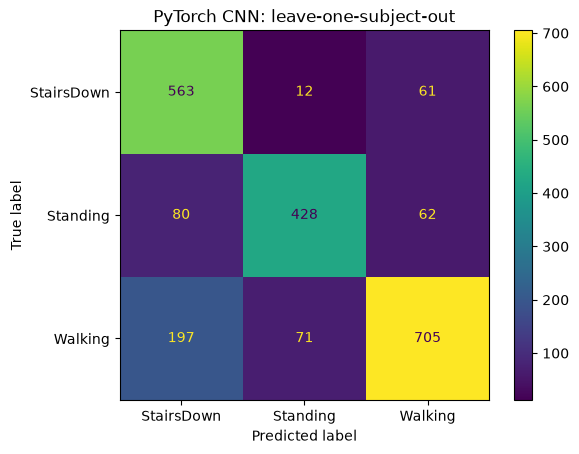

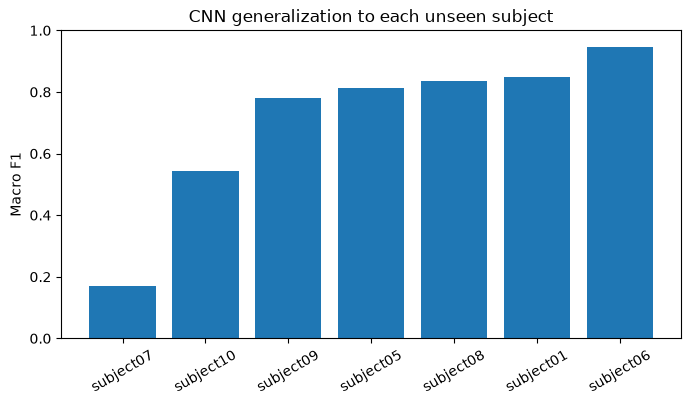

In [44]:
print(
    classification_report(
        y_int,
        cnn_pred,
        target_names=class_names,
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_int,
    cnn_pred,
    display_labels=class_names,
    cmap=None,
)

plt.title(
    "PyTorch CNN: leave-one-subject-out"
)

plt.show()


fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    cnn_subject_scores["subject_id"],
    cnn_subject_scores["macro_f1"],
)

ax.set_ylim(0, 1)
ax.set_ylabel("Macro F1")
ax.set_title(
    "CNN generalization to each unseen subject"
)

plt.xticks(rotation=30)

plt.show()


## 24. Compare hand-designed features with learned features

Our reference Notebook 06 results were approximately:

```text
Logistic Regression + hand features   macro F1 ≈ 0.638
Random Forest + hand features         macro F1 ≈ 0.660
```

Now compare the raw-waveform CNN.

Do **not** assume deep learning must win.

We have thousands of overlapping windows, but only seven independent development people. For generalization to new humans, the number of people may be the tighter sample-size bottleneck.


,model,macro_f1
0,Logistic Regression + hand features,0.63800
1,Random Forest + hand features,0.66000
2,1D CNN + raw waveform,0.77921


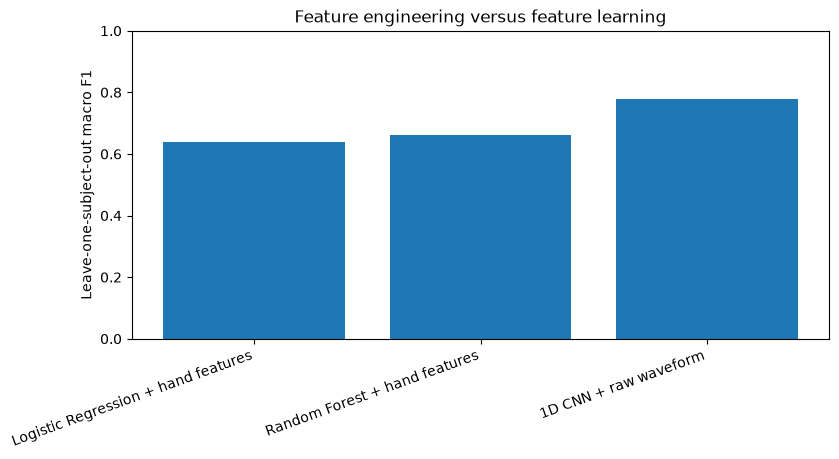

In [45]:
comparison = pd.DataFrame({
    "model": [
        "Logistic Regression + hand features",
        "Random Forest + hand features",
        "1D CNN + raw waveform",
    ],
    "macro_f1": [
        0.638,
        0.660,
        cnn_macro_f1,
    ],
})

display(comparison)


fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(
    comparison["model"],
    comparison["macro_f1"],
)

ax.set_ylim(0, 1)
ax.set_ylabel(
    "Leave-one-subject-out macro F1"
)

ax.set_title(
    "Feature engineering versus feature learning"
)

plt.xticks(
    rotation=20,
    ha="right",
)

plt.show()


## 25. Eventually: train the frozen model for the hidden challenge

Do not use the hidden test set while choosing architecture or hyperparameters.

A defensible final sequence is:

```text
development subjects only
        ↓
grouped CV chooses model recipe
        ↓
freeze architecture / settings
        ↓
choose final epoch count from grouped-CV histories
        ↓
train one final model on ALL development subjects
        ↓
open hidden test X exactly once
        ↓
predict
```

For the competition test file, we will not have activity labels available to students.

That is the whole point of the vault.


# Final checkpoint

Be ready to explain these without code:

1. Why does PyTorch `Conv1d` expect `[batch, channels, time]`?
2. What exactly is stored in one first-layer convolution filter?
3. Why does weight sharing make Conv1d parameter-efficient?
4. What is a **feature map**?
5. What does ReLU do to convolution scores?
6. What does MaxPool1d do, and what information can pooling discard?
7. How can a width-5 deep kernel depend on much more than five original samples?
8. What does `AdaptiveAvgPool1d(1)` do to `time × filters`?
9. Why does `CrossEntropyLoss` want logits rather than softmax probabilities?
10. In the PyTorch training loop, what do `zero_grad()`, `backward()`, and `step()` each do?
11. Why do we calculate normalization statistics separately inside every subject-wise CV fold?
12. What changed between the randomly initialized and trained first-layer kernels?
13. What happened to early feature maps when we shifted the waveform in time?
14. Did the final pooled representation change as much as the early feature map?
15. Did the CNN beat Logistic Regression and Random Forest on unseen people?
16. If we have thousands of overlapping windows but only seven people, what is the more important sample-size limitation?

The big conceptual bridge:

```text
Traditional ML
humans choose representation
        ↓
model learns decision boundary


CNN
network learns representation
        ↓
network learns decision boundary
```
